# Introdução às Redes Neurais e Deep Learning

## O Perceptron Multicamada - Continuação

### Solução de problemas de Regressão/Classificação com Keras & Tensorflow

#### Importação de bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
import tensorflow as tf
import keras
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras import backend
from tensorflow.keras.utils import to_categorical

In [2]:
class PrintEvery100(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % 100 == 0:
            print(f"Época {epoch + 1}: loss = {logs['loss']:.6f}")

In [3]:
def plot_test(X,y,model) :
    X_test = np.linspace(0,1, 1000)
    yhat = model.predict(X_test)

    fig = plt.figure(figsize=(5, 5))
    plt.scatter(X, y, label="Train data")
    plt.plot(X_test, yhat, color="red", label="Prediction")
    plt.xlabel('x', fontsize=14)
    plt.ylabel('y', fontsize=14)
    plt.legend(loc="best", fontsize=11)
    plt.show()

#### **Regressão Linear**

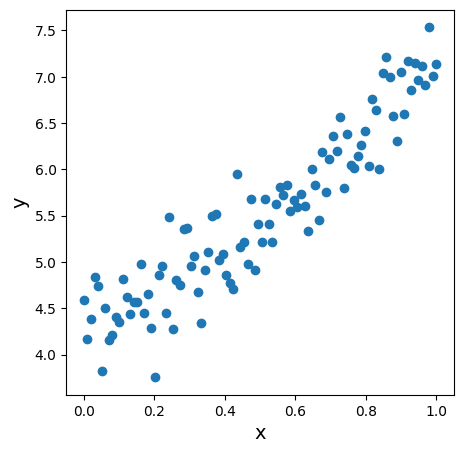

In [4]:
np.random.seed(0)
num_points = 100
X1 = np.linspace(0,1, num_points)
y1 = 4 + 3 * X1 + np.random.randn(num_points)/3

fig = plt.figure(figsize=(5, 5))
plt.scatter(X1, y1)
plt.xlabel('x', fontsize=14)
plt.ylabel('y', fontsize=14)
plt.show()

* Uma camada com um neurônio

In [5]:
np.random.seed(0)
random.seed(0)
tf.random.set_seed(0)
model1 = Sequential([
  Input(shape=(1,)),
  Dense(1, activation='linear'),
])
model1.compile(optimizer='adam', loss='mse', metrics=['mse'])
model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 1)                   │               2 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
history1 = model1.fit(X1, y1, epochs=1500, verbose=0,
                      batch_size=32,callbacks=[PrintEvery100()])

Época 100: loss = 24.753681
Época 200: loss = 19.471712
Época 300: loss = 15.055065
Época 400: loss = 11.401672
Época 500: loss = 8.422864
Época 600: loss = 6.039799
Época 700: loss = 4.180168
Época 800: loss = 2.775459
Época 900: loss = 1.758618
Época 1000: loss = 1.062583
Época 1100: loss = 0.619989
Época 1200: loss = 0.364648
Época 1300: loss = 0.234972
Época 1400: loss = 0.178995
Época 1500: loss = 0.158869


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


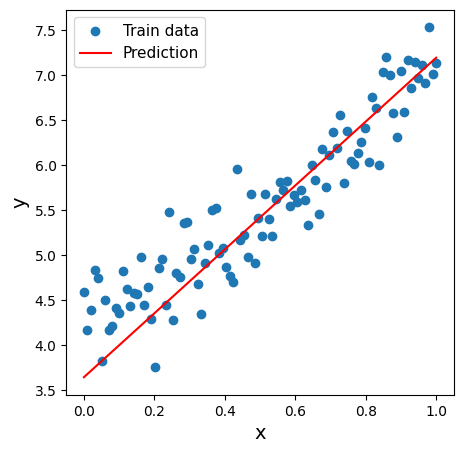

In [7]:
plot_test(X1,y1,model1)

* Rede com múltiplas camadas

In [8]:
np.random.seed(15)
random.seed(15)
tf.random.set_seed(15)
model2 = Sequential([
  Input(shape=(1,)),
  Dense(50, activation='linear'),
  Dense(1,activation='linear'),
])
model2.compile(optimizer='adam', loss='mse', metrics=['mse'])
model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                      │ (None, 50)                  │             100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 151 (604.00 B)

 Trainable params: 151 (604.00 B)

 Non-trainable params: 0 (0.00 B)

In [9]:
history2 = model2.fit(X1, y1, epochs=400, verbose=0,
                      batch_size=32,callbacks=[PrintEvery100()])

Época 100: loss = 0.156789
Época 200: loss = 0.123737
Época 300: loss = 0.115460
Época 400: loss = 0.114693


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


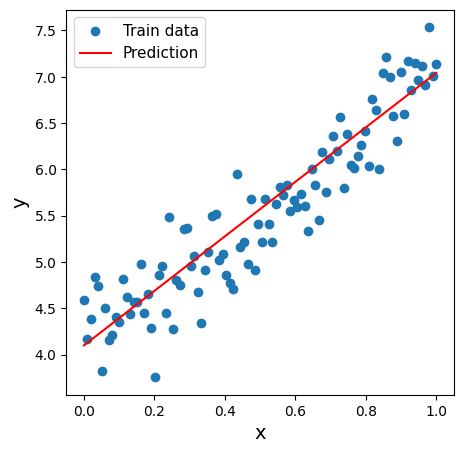

In [10]:
plot_test(X1,y1,model2)

#### **Regressão quadrática**

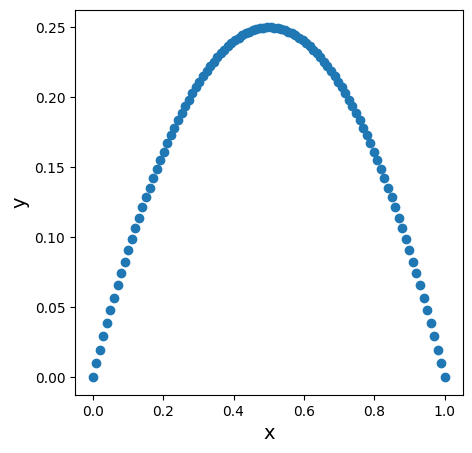

In [11]:
np.random.seed(0)
num_points = 100
X2 = np.linspace(0,1, num_points)
y2 = -(X2-0.5)**2 + 0.25

fig = plt.figure(figsize=(5, 5))
plt.scatter(X2, y2)
plt.xlabel('x', fontsize=14)
plt.ylabel('y', fontsize=14)
plt.show()


* Uma camada com um neurônio

In [12]:
np.random.seed(0)
random.seed(0)
tf.random.set_seed(0)

model3 = Sequential([
  Input(shape=(1,)),
  Dense(1, activation='relu'),
])
model3.compile(optimizer='adam', loss='mse', metrics=['mse'])
model3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 1)                   │               2 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

In [13]:
history3 = model3.fit(X2, y2, epochs=1500, verbose=0,
                      batch_size=32,callbacks=[PrintEvery100()])

Época 100: loss = 0.006314
Época 200: loss = 0.005878
Época 300: loss = 0.005827
Época 400: loss = 0.005821
Época 500: loss = 0.005820
Época 600: loss = 0.005820
Época 700: loss = 0.005820
Época 800: loss = 0.005820
Época 900: loss = 0.005820
Época 1000: loss = 0.005820
Época 1100: loss = 0.005820
Época 1200: loss = 0.005820
Época 1300: loss = 0.005820
Época 1400: loss = 0.005820
Época 1500: loss = 0.005820


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


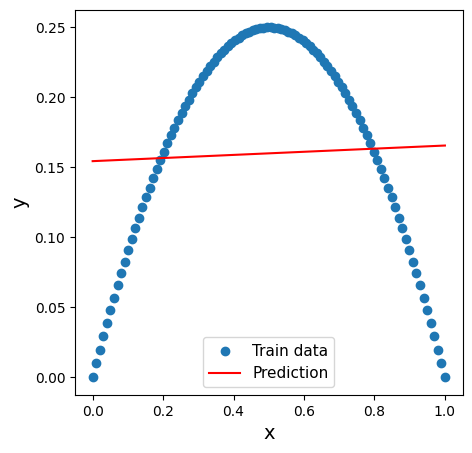

In [14]:
plot_test(X2,y2,model3)


* Rede com múltiplas camadas

In [15]:
np.random.seed(15)
random.seed(15)
tf.random.set_seed(15)

model4 = Sequential([
  Input(shape=(1,)),
  Dense(100, activation='relu'),
  Dense(1,activation='linear'),
])

model4.compile(optimizer='adam', loss='mse', metrics=['mse'])
model4.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                      │ (None, 100)                 │             200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │             101 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 301 (1.18 KB)

 Trainable params: 301 (1.18 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
history4 = model4.fit(X2, y2, epochs=700, verbose=0,
                      batch_size=32,callbacks=[PrintEvery100()])

Época 100: loss = 0.002114
Época 200: loss = 0.000750
Época 300: loss = 0.000283
Época 400: loss = 0.000110
Época 500: loss = 0.000047
Época 600: loss = 0.000023
Época 700: loss = 0.000012


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


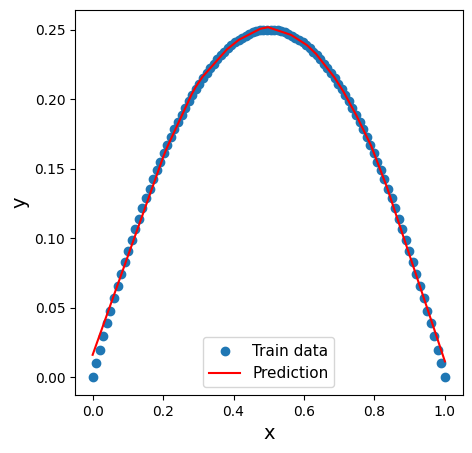

In [17]:
plot_test(X2,y2,model4)

#### **Classificação (Regressão Logística)**

In [36]:
from keras.datasets import mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [37]:
# Normalize the images.
train_images = (X_train / 255) - 0.5
test_images = (X_test / 255) - 0.5

# Flatten the images.
train_images = train_images.reshape((-1, 784))
test_images = test_images.reshape((-1, 784))

In [38]:
model5 = Sequential([
  Input(shape=(784,)),
  Dense(64, activation='relu'),
  Dense(64, activation='relu'),
  Dense(10, activation='softmax'),
])
model5.compile(
  optimizer='adam',
  loss='categorical_crossentropy',
  metrics=['accuracy'],
)
model5.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                     │ (None, 64)                  │          50,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
model5.fit(train_images,to_categorical(y_train),epochs=5,batch_size=32)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8196 - loss: 0.5734
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9410 - loss: 0.1982
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9547 - loss: 0.1485
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9619 - loss: 0.1247
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9662 - loss: 0.1078


In [40]:
model5.evaluate(
  test_images,
  to_categorical(y_test)
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9585 - loss: 0.1394


[0.11480965465307236, 0.9642999768257141]

In [49]:
predictions = model5.predict(test_images[:35])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


In [51]:
# Imprime a s predições.
print(np.argmax(predictions, axis=1)) 

# e compara com os rótulos reais.
print(y_test[:35]) # [7, 2, 1, 0, 4 ...]

[7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4 9 6 6 5 4 0 7 4 0 1 3 1 3 4 7]
[7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4 9 6 6 5 4 0 7 4 0 1 3 1 3 4 7]


#### **Previsão de consumo elétrico com a base de dados PJME_hourly**

A base PJME_hourly.csv contém  os dados de consumo de energia por hora e por dia da PJM Interconnection LLC (PJM), uma organização regional de transmissão (RTO) nos Estados Unidos que supervisiona o sistema de transmissão de energia elétrica na região leste. O conjunto de dados abrange o período de 2002 a 2018 e contém 145.336 registros horários e 6.057 registros diários. O conjunto de dados está disponível publicamente em

https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption?select=PJME_hourly.csv

In [25]:
from tensorflow import keras
from keras.models import Sequential
from keras.layers import LSTM, Dense,Input
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

* Inicialmente o pandas lê o arquivo CSV e cria um dataframe.
* O pandas converte a coluna *Datetime*, que inicialmente é composta por *strings* de texto, em objetos de data/hora que possam ser reconhecidos como valores reais. Por exemplo, '2002-01-01 01:00'é convertido em Timestamp('2002-01-01 01:00:00'). Isto é necessário porque séries temporais precisam de valores reais para todo tipo de processamento posterior.
* Estabelece a coluna *Datetime* como índice temporal da base de dados.
* O pandas reorganiza os dados para frequência horária (`resample('h')`), garantindo que a sequência de dados seja regular, com espaçamento temporal constante  e sem valores nulos. `mean()` agrega valores de múltiplos registros dentro da mesma horae substitui pela média. `ffill()` preenche os valores criados em `resample('h')` com os últimos valores válidos anteriores. Em séries temporais como esta os valores consecutivos costumam ser correlacionados, e manter o último valor quando uma nova amostra é criada preserva a continuidade temporal. 

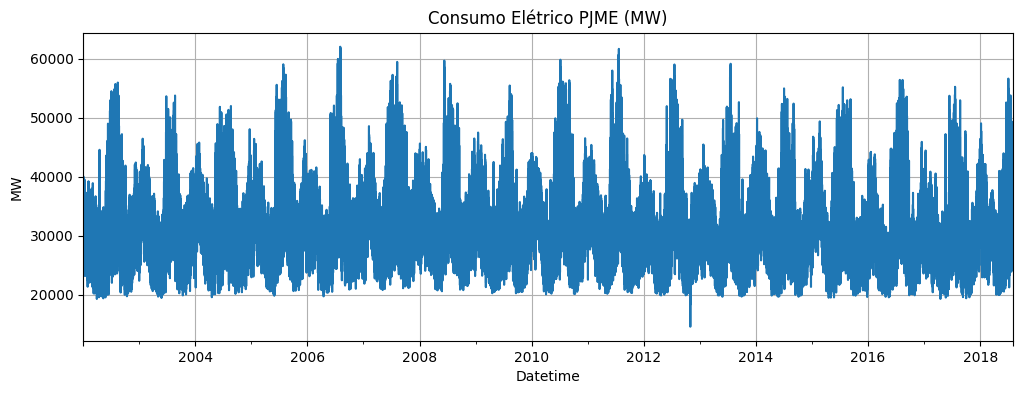

In [26]:
# Carregar dados públicos de consumo horário PJME
df = pd.read_csv("Files\PJME_hourly.csv")
df['Datetime'] = pd.to_datetime(df['Datetime'])  # converte string para datetime
df = df.set_index('Datetime')                   # define como índice
df = df.resample('h').mean().ffill()  # Garantir frequência horária e sem valores nulos

# Visualização dos dados
df.plot(figsize=(12, 4), title='Consumo Elétrico PJME (MW)', legend=False)
plt.ylabel("MW")
plt.grid(True)
plt.show()

* Valores muito grandes na base de dados podem causar explosão de gradientes, treinamento instável e saturação das funções de ativação sigmoide ou tanh. Por isso, MinMaxScaler() transforma os dados em um intervalo como [0,1]. Para isso ele aplica
* A rede não processa a série temporal inteira de uma vez, mas por sequências de tamanho fixo, onde ela aprende para cada sequência a prever os valores futuros. Neste caso são formadas sequências de 24 horas e previstas as próximas 6 horas.
* Após `create_sequences()`, cada elemento de X contém uma sequência de 24 hrs, e cada elemento de y contém as 6 horas futuras correspondentes ao mesmo elemento de X. Importante: `X[0,:]` conterá uma janela de 0 à 23hrs, e `y[0,:]` conterá as próximas 6 horas, ou seja, de 24 a 29 horas. Por sua vez, `X[1,:]` contém uma janela 1 a 24 horas, e `y[1,:]` contém de 25 a 30 horas. A cada intervalo a janela "escorrega" apenas uma hora.

In [56]:
# Normalização dos dados
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(df)

# 3. Função para criar janelas
def create_sequences(data, window_size=24, forecast_horizon=6):
    X, y = [], []
    for i in range(len(data) - window_size - forecast_horizon + 1):
        X.append(data[i:i+window_size]) # Cria o *array* de sequências de 24 horas
        y.append(data[i+window_size:i+window_size+forecast_horizon]) # o label(alvo) são as próximas 6 horas. 
    return np.array(X), np.array(y)

# Parâmetros
window_size = 24   # últimas 24 horas
forecast_horizon = 6  # prever as próximas 6 horas

X, y = create_sequences(scaled_data, window_size, forecast_horizon)

# Dividir em treino e teste
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]
print('formato X_train é', X_train.shape)
X_train_dense = X_train.reshape(X_train.shape[0], 24)
X_test_dense = X_test.reshape(X_test.shape[0], 24)
print('formato X_train_dense é', X_train_dense.shape)

y_train_dense = y_train.reshape(y_train.shape[0], 6)
y_test_dense = y_test.reshape(y_test.shape[0], 6)

formato X_train é (116290, 24, 1)
formato X_train_dense é (116290, 24)


In [28]:
model6 = keras.Sequential([
    keras.Input(shape=(24,)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(6, activation='linear')
])
model6.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

model6.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                      │ (None, 64)                  │           1,600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 6)                   │             198 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,878 (15.15 KB)

 Trainable params: 3,878 (15.15 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
# Treinar modelo
history = model6.fit(X_train_dense, y_train_dense, epochs=50, batch_size=32, validation_split=0.1,shuffle=False
)#10% para validação dos dados

Epoch 1/50
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.0097 - mae: 0.0544 - val_loss: 0.0015 - val_mae: 0.0294
Epoch 2/50
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 0.0013 - mae: 0.0273 - val_loss: 0.0014 - val_mae: 0.0284
Epoch 3/50
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 0.0011 - mae: 0.0251 - val_loss: 0.0013 - val_mae: 0.0270
Epoch 4/50
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 0.0010 - mae: 0.0238 - val_loss: 0.0012 - val_mae: 0.0267
Epoch 5/50
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 9.6637e-04 - mae: 0.0229 - val_loss: 0.0012 - val_mae: 0.0260
Epoch 6/50
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 9.0607e-04 - mae: 0.0221 - val_loss: 0.0011 - val_mae: 0.0255
Epoch 7/50
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 8.6356e-04 - mae: 0.0216 - val_loss: 0.0011 - val_mae: 0.0248
Epoch 8/50
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 8.3124e-04 - mae: 0.0211 - val_loss: 0.0011 - val_mae: 0.0244
Epoch 9/50
3271/3271 ━━━

909/909 ━━━━━━━━━━━━━━━━━━━━ 1s 928us/step
Horizonte 1h - RMSE: 566.27 MW
Horizonte 2h - RMSE: 883.74 MW
Horizonte 3h - RMSE: 1237.87 MW
Horizonte 4h - RMSE: 1545.51 MW
Horizonte 5h - RMSE: 1793.76 MW
Horizonte 6h - RMSE: 2103.70 MW


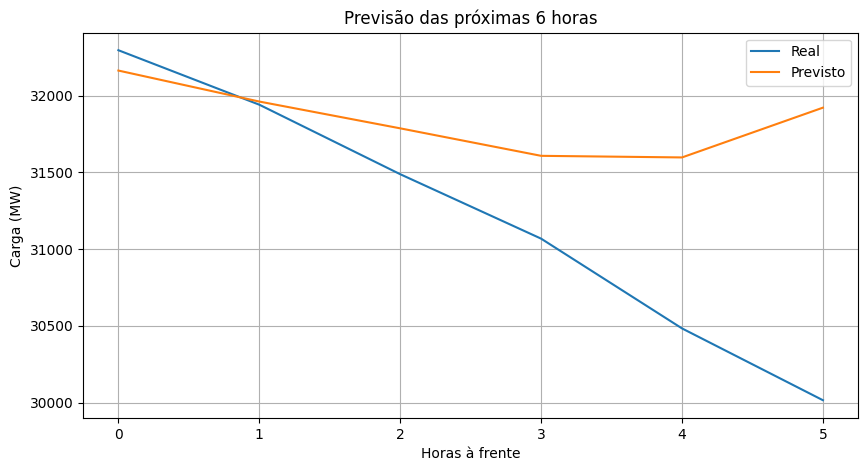

In [30]:
# Previsões
y_pred = model6.predict(X_test)

# 8. Inverter normalização: Converte osdados de um tensor 3D para um tensor 2D de forma 
# que o inverse_tranformam() possa inverter a normalização e depois restaura o formato original dos dados. 
y_test_inv = scaler.inverse_transform(y_test.reshape(-1, 1)).reshape(y_test.shape)
y_pred_inv = scaler.inverse_transform(y_pred.reshape(-1, 1)).reshape(y_pred.shape)

# 9. Avaliação por horizonte
for h in range(forecast_horizon):
    rmse = np.sqrt(mean_squared_error(y_test_inv[:, h], y_pred_inv[:, h]))#Erro qudrático médio
    mae = mean_absolute_error(y_test_inv[:, h], y_pred_inv[:, h])# Erro absoluto médio
    print(f'Horizonte {h+1}h - RMSE: {rmse:.2f} MW')

# 10. Visualização para 1 exemplo
plt.figure(figsize=(10, 5))
plt.plot(range(6), y_test_inv[24], label='Real')
plt.plot(range(6), y_pred_inv[24], label='Previsto')
plt.xlabel('Horas à frente')
plt.ylabel('Carga (MW)')
plt.title('Previsão das próximas 6 horas')
plt.legend()
plt.grid(True)
plt.show()